# Iterative wall localization with non-parallel links

A copy of the iterative wall localization of `reconstruction.ipynb`, for tag pairs at any angle to the walls instead
of only the parallel ones. The models still see only the link's θ̂ and α̂: no direction, length or location input.

**Link to wall distance.** For a non-parallel link, "its distance from the wall" has to be defined. Two definitions
are compared:

- **`perp`: perpendicular ray from the link's centre.** Cast a ray from the midpoint, perpendicular to the link, both
  ways. The distance is how far the ray goes before it meets a wall. For a parallel link this is the old target. For a
  45° link, the ray meets the wall obliquely and is √2 times longer than the midpoint's distance from that wall.
- **`tag`: closest tag to the nearest wall.** The perpendicular distance from whichever of the link's two tags is
  closest to any wall. For a parallel link it can differ from the old target, since the nearest wall can be one the
  link is perpendicular to.

The whole algorithm is run with each definition, and the two are compared on prediction error and on the final
walls. `TARGET` (first code cell) picks the one drawn in the stage, error and room figures.

**Where the walls can be.** The four walls are assumed to be aligned with the tag grid, as before. A wall is then
a position on one of two axes: across the rows (Row-1 and Row-8 walls) or across the columns (Edge02 and Edge01).
Each link's predicted distance gives candidate wall positions on those axes. The candidates depend on the definition
(see *Localization* below).

In [1]:
import contextlib
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from roomsweeps_wall_distance import (DATA_DIR, FREQ_RANGE, MESH_PATH, N_COLS, N_ROWS, ROOT, TILE_CM, WALL_Z,
                                      all_positions, build_dataset, find_walls, grid_xy, label_grid, load_bidir,
                                      wall_distance_cm)
from roomsweeps_wall_distance import models as sk_models
from roomsweeps_wall_distance_alllinks import perpendicular_hit

# Tag pairs used, as (columns apart, rows apart). (1, 0) and (0, 1) are the 46 cm parallel links, (1, 1) the 65 cm
# diagonals, (1, 2) and (2, 1) the 103 cm knight's moves.
LINK_OFFSETS = {(1, 0), (0, 1), (1, 1)}
TARGETS = {"perp": "perpendicular ray from the link's centre", "tag": "closest tag to the nearest wall"}
TARGET = "tag"                       # the definition drawn in the stage, error and room figures

ITER_CAPS_CM = (200, 150, 100, 50)   # Model_X for each X; the classifier asks whether the wall is more than 200 cm away
CLASSIFIER = "SVC"                   # "SVC" or "MLP"
ITER_CUTOFF = 0.65                   # a side's wall is accepted only where its support reaches this
ITER_FALLBACK = False                # after the initial step, retry the sides without a wall with all links, Model_∞
ITER_SIGMA_MIN_CM = 10               # floor on σ along an axis
INNER_FOLDS = 5                      # folds over the training experiments that estimate σ without test truth
MIN_TRAIN = 10                       # a Model_X with fewer training links in a fold predicts nothing there
ITER_TOL_CM = 30                     # scoring only: a candidate within this of its link's wall counts as correct
MODEL = "SVR"                        # "SVR" or "MLP" (roomsweeps_wall_distance.models)
SEED = 0
OUT = ROOT / "reconstruction_nonparallel_out"
OUT.mkdir(exist_ok=True)

assert TARGET in TARGETS
BUILD = lambda X, y: sk_models(SEED)[MODEL].fit(X, y)
CLASSIFIERS = {
    "SVC": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10.0, gamma="scale", class_weight="balanced")),
    "MLP": lambda: make_pipeline(StandardScaler(), MLPClassifier((64, 32), alpha=1e-2, max_iter=5000, random_state=SEED)),
}

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Data: links, features and geometry

Every tag pair of every experiment whose grid offset is in `LINK_OFFSETS`. The features are the median θ̂ and α̂ over
the link's runs, as in `roomsweeps_wall_distance.build_dataset`.

All positions below are in the tag grid's own frame, from the marker grid only: `U[0]` is the unit vector across
the rows, `U[1]` across the columns, and a point's position on axis d is its distance along `U[d]` from grid (0, 0),
in cm. The scanned walls are not used for this.

In [2]:
positions = all_positions()
exps = [e for e in positions if any((DATA_DIR / e).glob("*.csv"))]
walls = find_walls()
bidir = {e: load_bidir(e) for e in exps}

rows = []
for exp in exps:
    pos = positions[exp]
    tags = sorted(pos.index)
    for i, ta in enumerate(tags):
        for tb in tags[i + 1:]:
            la, lb = pos.loc[ta, "label"], pos.loc[tb, "label"]
            (ca, ra), (cb, rb) = label_grid(la), label_grid(lb)
            if (abs(ca - cb), abs(ra - rb)) in LINK_OFFSETS:
                rows.append({"exp": exp, "T1": ta, "T2": tb, "label_a": la, "label_b": lb,
                             "offset": (abs(ca - cb), abs(ra - rb)), "wall_cm": np.nan})
with contextlib.redirect_stdout(io.StringIO()):
    X_all, _, meta_all, FREQS = build_dataset(pd.DataFrame(rows), bidir, FREQ_RANGE)

# grid frame
O = grid_xy(0, 0)
_unit = lambda v: v / np.linalg.norm(v)
U = {0: _unit(np.mean([grid_xy(c, N_ROWS - 1) - grid_xy(c, 0) for c in range(N_COLS)], 0)),    # across rows
     1: _unit(np.mean([grid_xy(N_COLS - 1, r) - grid_xy(0, r) for r in range(N_ROWS)], 0))}    # across columns
grid_s = lambda xy, d: 100 * (np.asarray(xy) - O) @ U[d]
AXIS = {0: "across the rows (Row-1 / Row-8 walls)", 1: "across the columns (Edge02 / Edge01 walls)"}

A_xy = np.array([grid_xy(*label_grid(l)) for l in meta_all["label_a"]])
B_xy = np.array([grid_xy(*label_grid(l)) for l in meta_all["label_b"]])
u_link = (B_xy - A_xy) / np.linalg.norm(B_xy - A_xy, axis=1, keepdims=True)
normal = np.column_stack([-u_link[:, 1], u_link[:, 0]])
C = np.column_stack([grid_s((A_xy + B_xy) / 2, d) for d in (0, 1)])     # midpoint on each axis
S_A = np.column_stack([grid_s(A_xy, d) for d in (0, 1)])                # tag a on each axis
S_B = np.column_stack([grid_s(B_xy, d) for d in (0, 1)])                # tag b on each axis
P = np.column_stack([normal @ U[d] for d in (0, 1)])                    # axis cm per cm along the normal

exp_all = meta_all["exp"].to_numpy()
pair_all = np.array(["-".join(map(str, sorted(p))) for p in zip(meta_all["label_a"], meta_all["label_b"])])
okey = lambda o: f"{o[0]}×{o[1]}"                                       # (1, 1) -> "1×1"
offset_all = np.array([okey(o) for o in meta_all["offset"]])
parallel = np.array([0 in o for o in meta_all["offset"]])
all_labels = sorted({l for p in positions.values() for l in p["label"]})
TAGS = {d: (min(s), max(s)) for d in (0, 1) for s in [[grid_s(grid_xy(*label_grid(l)), d) for l in all_labels]]}
S_IT = {d: np.arange(TAGS[d][0] - 500, TAGS[d][1] + 500, 2.0) for d in (0, 1)}

length = lambda k: TILE_CM * np.hypot(*map(int, k.split("×")))
print(f"{len(exps)} experiments, {len(meta_all)} links:")
for o in sorted(set(offset_all)):
    print(f"  {o} ({length(o):.0f} cm, {'parallel' if '0' in o.split('×') else 'non-parallel'}): {(offset_all == o).sum()} links")

15 experiments, 570 links:
  0×1 (46 cm, parallel): 180 links
  1×0 (46 cm, parallel): 150 links
  1×1 (65 cm, non-parallel): 240 links


## The two link to wall distances

These are the training targets and are used for scoring only. They come from the scanned walls.

- **`perp`**: `perpendicular_hit` of `roomsweeps_wall_distance_alllinks.py`. A ray from the midpoint, perpendicular
  to the link, cast both ways. The distance is how far it goes before meeting the first wall.
- **`tag`**: the smallest perpendicular distance from either tag to any of the four walls.

The figure shows both for a few links. The table gives each target's range per link type.

In [3]:
def true_targets():
    out = {"perp": ([], []), "tag": ([], [])}
    for a, b in zip(A_xy, B_xy):
        h = perpendicular_hit(a, b, walls)
        out["perp"][0].append(h["wall_cm"]); out["perp"][1].append(h["wall"])
        dist = {(n, k): wall_distance_cm(t, w) for n, w in walls.items() for k, t in enumerate((a, b))}
        key = min(dist, key=dist.get)
        out["tag"][0].append(dist[key]); out["tag"][1].append(key[0])
    return {t: (np.array(v), np.array(w)) for t, (v, w) in out.items()}

TRUTH = true_targets()                      # target -> (distance cm, name of the wall it measures to)
Y = {t: v for t, (v, _) in TRUTH.items()}

pd.DataFrame([{"link": f"{o} {length(o):.0f} cm", "links": int((offset_all == o).sum()),
               **{f"{t} median (cm)": np.median(Y[t][offset_all == o]) for t in TARGETS},
               **{f"{t} ≤ {ITER_CAPS_CM[0]} cm (%)": 100 * (Y[t][offset_all == o] <= ITER_CAPS_CM[0]).mean() for t in TARGETS},
               **{f"{t} ≤ 50 cm": int((Y[t][offset_all == o] <= 50).sum()) for t in TARGETS}}
              for o in sorted(set(offset_all))]).set_index("link").round(0)

,links,perp median (cm),tag median (cm),perp ≤ 200 cm (%),tag ≤ 200 cm (%),perp ≤ 50 cm,tag ≤ 50 cm
link,,,,,,,
0×1 46 cm,180,246.0,84.0,33.0,100.0,0,45
1×0 46 cm,150,128.0,113.0,80.0,88.0,30,30
1×1 65 cm,240,154.0,84.0,60.0,100.0,0,60


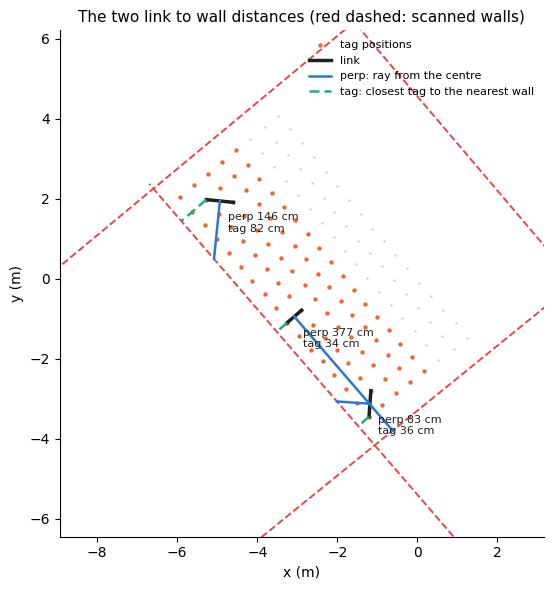

In [4]:
# a few example links, drawn with both distances
def wall_segment(p, n, half=8):
    u = np.array([-n[1], n[0]])
    return p + np.outer([-half, half], u)

grid_pts = np.array([grid_xy(c, r) for c in range(N_COLS) for r in range(N_ROWS)])
tag_xy = np.array([grid_xy(*label_grid(l)) for l in all_labels])
pick = [np.flatnonzero((offset_all == o) & (exp_all == e))[k] for o, e, k in
        [("1×1", exp_all[0], 0), ("1×1", exp_all[-1], 5), ("0×1", "8", 4)] if ((offset_all == o) & (exp_all == e)).sum() > k]
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(*grid_pts.T, s=3, color="#cfcfcf", lw=0)
ax.scatter(*tag_xy.T, s=10, color="#eb6834", lw=0, label="tag positions")
for n_, (p, nrm, _) in walls.items():
    ax.plot(*wall_segment(p, nrm).T, color="#e34948", ls="--", lw=1.4)
for k, i in enumerate(pick):
    a, b = A_xy[i], B_xy[i]
    ax.plot(*np.array([a, b]).T, color="#1f1f1f", lw=2.5, label="link" if k == 0 else None)
    h = perpendicular_hit(a, b, walls)
    mid = (a + b) / 2
    ax.plot([mid[0], h["hit_x"]], [mid[1], h["hit_y"]], color="#2a78d6", lw=1.8,
            label="perp: ray from the centre" if k == 0 else None)
    p, nrm, _ = walls[TRUTH["tag"][1][i]]
    t = min((a, b), key=lambda q: wall_distance_cm(q, walls[TRUTH["tag"][1][i]]))
    foot = t - (t - p) @ nrm * nrm
    ax.plot([t[0], foot[0]], [t[1], foot[1]], color="#1baf7a", lw=1.8, ls=(0, (4, 2)),
            label="tag: closest tag to the nearest wall" if k == 0 else None)
    ax.annotate(f"perp {Y['perp'][i]:.0f} cm\ntag {Y['tag'][i]:.0f} cm", mid, xytext=(6, -22), textcoords="offset points",
                fontsize=8, color="#1f1f1f")
lo_xy, hi_xy = tag_xy.min(0) - 3, tag_xy.max(0) + 3
ax.set_xlim(lo_xy[0], hi_xy[0]); ax.set_ylim(lo_xy[1], hi_xy[1]); ax.set_aspect("equal")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title("The two link to wall distances (red dashed: scanned walls)", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "targets.png", dpi=130)
plt.show()

## Models

For each target, as in `reconstruction.ipynb`:

- **Model_X**, for each X in `ITER_CAPS_CM`: `MODEL` trained on the training links whose target is at most X. It
  predicts all of the held-out experiment's links. If a fold has fewer than `MIN_TRAIN` training links within X, it
  predicts nothing there, and that stage has no links.
- **Model_∞**: trained on all training links. Used only by the fallback.
- **The classifier**: is the target more than 200 cm?

Everything is leave one experiment out, with the held-out experiment's label pairs dropped from training. σ of
every model, per held-out experiment, is the RMSE of a `INNER_FOLDS`-fold cross-validation over the training
experiments only, floored at `ITER_SIGMA_MIN_CM`.

In [5]:
def loo_folds(train_mask):
    # (held-out experiment, train, test) indices; the held-out label pairs are dropped from training
    for exp in dict.fromkeys(exp_all):
        te = np.flatnonzero(exp_all == exp)
        yield exp, np.flatnonzero((exp_all != exp) & ~np.isin(pair_all, pair_all[te]) & train_mask), te

def regressor_loo(y, cap):
    within = np.ones(len(y), bool) if cap is None else y <= cap
    pred, sigma = np.full(len(y), np.nan), np.full(len(y), np.nan)
    for exp, tr, te in loo_folds(within):
        if len(tr) < MIN_TRAIN:
            continue
        pred[te] = BUILD(X_all[tr], y[tr]).predict(X_all[te])
        tr_exps, err = list(dict.fromkeys(exp_all[tr])), []
        for k in range(INNER_FOLDS):
            ite = tr[np.isin(exp_all[tr], tr_exps[k::INNER_FOLDS])]
            itr = tr[~np.isin(exp_all[tr], tr_exps[k::INNER_FOLDS]) & ~np.isin(pair_all[tr], pair_all[ite])]
            if len(ite) and len(itr) >= MIN_TRAIN // 2:
                err.append(BUILD(X_all[itr], y[itr]).predict(X_all[ite]) - y[ite])
        sigma[te] = max(np.sqrt((np.concatenate(err) ** 2).mean()), ITER_SIGMA_MIN_CM) if err else np.nan
    return {"pred": pred, "sigma": sigma}

def mean_loo(y, cap):
    # baseline: the mean target of the fold's training links within cap
    within = np.ones(len(y), bool) if cap is None else y <= cap
    out = np.full(len(y), np.nan)
    for exp, tr, te in loo_folds(within):
        if len(tr):
            out[te] = y[tr].mean()
    return out

def auc(score, label):
    pos, neg = score[label], score[~label]
    return (pos[:, None] > neg[None]).mean() + 0.5 * (pos[:, None] == neg[None]).mean()

reg, near_pred, clf_stats = {}, {}, {}
for t in TARGETS:
    y = Y[t]
    with contextlib.redirect_stdout(io.StringIO()):
        reg[t] = {cap: regressor_loo(y, cap) for cap in (*ITER_CAPS_CM, None)}
    far_true = y > ITER_CAPS_CM[0]
    far_pred, score = np.zeros(len(y), bool), np.full(len(y), np.nan)
    for exp, tr, te in loo_folds(np.ones(len(y), bool)):
        if len(set(far_true[tr])) < 2:                       # one class only: it is the answer
            far_pred[te], score[te] = far_true[tr][0], float(far_true[tr][0])
            continue
        clf = CLASSIFIERS[CLASSIFIER]().fit(X_all[tr], far_true[tr])
        far_pred[te] = clf.predict(X_all[te])
        score[te] = clf.decision_function(X_all[te]) if hasattr(clf, "decision_function") else clf.predict_proba(X_all[te])[:, 1]
    near_pred[t] = ~far_pred
    clf_stats[t] = {"called near": int((~far_pred).sum()), "truly near (%)": 100 * (~far_true[~far_pred]).mean(),
                    "near found (%)": 100 * (~far_pred[~far_true]).mean(),
                    "AUC": auc(score, far_true) if 0 < far_true.sum() < len(y) else np.nan}

rows = []
for t in TARGETS:
    y = Y[t]
    for cap in (*ITER_CAPS_CM, None):
        m = np.ones(len(y), bool) if cap is None else y <= cap
        r, b = reg[t][cap], mean_loo(y, cap)
        ok = m & np.isfinite(r["pred"])
        rows.append({"target": t, "model": f"Model_{'∞' if cap is None else cap}", "links within X": int(m.sum()),
                     "MAE (cm)": np.abs(r["pred"] - y)[ok].mean() if ok.any() else np.nan,
                     "mean of train MAE (cm)": np.abs(b - y)[ok].mean() if ok.any() else np.nan,
                     "σ median (cm)": np.nanmedian(r["sigma"]) if np.isfinite(r["sigma"]).any() else np.nan})
pred_table = pd.DataFrame(rows).set_index(["target", "model"])
print("MAE on the held-out links within each model's X (the links the model is trained to predict)")
display(pred_table.round(1))
print(f"classifier {CLASSIFIER}, target > {ITER_CAPS_CM[0]} cm")
pd.DataFrame(clf_stats).T.round(2)

MAE on the held-out links within each model's X (the links the model is trained to predict)


links within X  MAE (cm)  mean of train MAE (cm)  \
target model                                                         
perp   Model_200             324      41.5                    39.7   
       Model_150             218      30.7                    28.4   
       Model_100             128      11.5                    17.4   
       Model_50               30       1.0                     0.9   
       Model_∞               570      85.7                    77.3   
tag    Model_200             552      41.6                    42.3   
       Model_150             435      30.3                    29.6   
       Model_100             288      16.8                    21.1   
       Model_50              135       1.5                     1.3   
       Model_∞               570      43.6                    44.7   

                  σ median (cm)  
target model                     
perp   Model_200           48.7  
       Model_150           37.3  
       Model_100           15.9  
       Model_50            10.0  
       Model_∞            105.4  
tag    Model_200           53.1  
       Model_150           37.5  
       Model_100           22.8  
       Model_50            10.0  
       Model_∞             55.3

classifier SVC, target > 200 cm


,called near,truly near (%),near found (%),AUC
perp,313.0,63.90,61.73,0.58
tag,554.0,96.93,97.28,0.80


## Localization

**Candidates.** A link with predicted distance d̂ gives candidate wall positions on the two axes:

- **`perp`**: the ray from the midpoint, both ways, ends at H = midpoint ± d̂ · n, where n is the link's normal. On
  axis d, H is at c_d ± d̂ · (n · U[d]). A side whose H lies among the tags on both axes is dropped, since no wall
  can be there. If H is beyond the tags on one axis, the wall it hit runs along the other axis: H is a candidate on
  that axis only. If it is beyond on both (a corner), it is a candidate on both, half each. The two sides of the
  link share its weight. On axis d, σ is scaled by |n · U[d]|, since the error is along the ray.
- **`tag`**: the nearest wall is d̂ from the closest tag, straight along an axis, on one of four sides. The
  candidates are min(tags) − d̂ and max(tags) + d̂ on each axis. Those among the tags are dropped, and the link's
  weight is shared by the rest.

**Localize.** On each axis, the candidates' Gaussians are summed over the selected links. The support is that sum,
scaled so that its highest point beyond the tags is 1. On each side of the tags, the wall is the support's peak,
kept if the support reaches `ITER_CUTOFF`. This is the method of `reconstruction.ipynb`. A parallel link has
n · U[d] = 0 on the other axis, so under `perp` it votes only on its own axis, as before.

**Steps.** As before:

1. The links the classifier calls near (≤ 200 cm), predicted by Model_200, localized.
2. Take those walls as the truth, and select every link within X of them. Under `perp` that is the length of the
   link's ray to the first estimated wall. Under `tag` it is its closest tag's distance to the nearest estimated
   wall. Predict with Model_X and localize again.
3. Repeat for X = 200, 150, 100 and 50 cm.

No ground truth is used. The scanned walls only grade the result.

In [6]:
def candidates(target, dhat):
    # (links, 4) candidate positions, their axis, weight (0 = dropped) and σ scale
    n = len(dhat)
    pos, ax, scale, group = np.zeros((n, 4)), np.zeros((n, 4), int), np.ones((n, 4)), np.zeros((n, 4), int)
    k = 0
    if target == "perp":
        for g, sign in enumerate((-1, 1)):                  # the two ends of the ray, H on each axis
            for d in (0, 1):
                pos[:, k], ax[:, k], scale[:, k], group[:, k] = C[:, d] + sign * dhat * P[:, d], d, np.abs(P[:, d]), g
                k += 1
    else:
        for d in (0, 1):                                    # the four sides, from the closest tag
            pos[:, k], ax[:, k], group[:, k] = np.minimum(S_A[:, d], S_B[:, d]) - dhat, d, k; k += 1
            pos[:, k], ax[:, k], group[:, k] = np.maximum(S_A[:, d], S_B[:, d]) + dhat, d, k; k += 1
    lo = np.where(ax == 0, TAGS[0][0], TAGS[1][0])
    hi = np.where(ax == 0, TAGS[0][1], TAGS[1][1])
    valid = ((pos < lo) | (pos > hi)) & (scale > 1e-3)
    w, n_groups = np.zeros((n, 4)), np.zeros(n)
    for g in np.unique(group):                              # equal over the groups that have a candidate, then
        m = group == g                                      # equal over that group's candidates
        cnt = (valid & m).sum(1)
        n_groups += cnt > 0
        w += np.where(m & valid, 1 / np.maximum(cnt, 1)[:, None], 0)
    return {"pos": pos, "axis": ax, "w": w / np.maximum(n_groups, 1)[:, None], "scale": scale}

def localize(target, sel, dhat, sigma, cutoff=ITER_CUTOFF):
    est, info = {}, {}
    m = np.flatnonzero(sel & np.isfinite(dhat))
    if not len(m):
        return est, info
    cand = candidates(target, np.nan_to_num(dhat))
    for d in (0, 1):
        on = (cand["w"] > 0) & (cand["axis"] == d)
        mm = m[on[m].any(1)]
        if not len(mm):
            continue
        mm = mm[np.argsort(C[mm, d], kind="stable")]
        s, (lo, hi) = S_IT[d], TAGS[d]
        sg = np.maximum(sigma[mm, None] * cand["scale"][mm], ITER_SIGMA_MIN_CM)[..., None]
        g = np.exp(-0.5 * ((s[None, None] - cand["pos"][mm, :, None]) / sg) ** 2) / (sg * np.sqrt(2 * np.pi))
        prof = (np.where(on[mm], cand["w"][mm], 0)[..., None] * g).sum((0, 1)) / len(m)
        beyond = (s < lo) | (s > hi)
        prof = prof / prof[beyond].max()
        est[d] = {side: s[r][np.argmax(prof[r])] for side, r in (("low", s < lo), ("high", s > hi))
                  if prof[r].max() >= cutoff}
        support = np.interp(cand["pos"][mm], s, prof)
        info[d] = {"idx": mm, "prof": prof, "beyond": beyond, "pos": cand["pos"][mm], "on": on[mm],
                   "keep": on[mm] & (support >= cutoff),
                   "voted": {"low": bool((on[mm] & (cand["pos"][mm] < lo)).any()),
                             "high": bool((on[mm] & (cand["pos"][mm] > hi)).any())}}
    return est, info

def distance_to(target, walls_est):
    # every link's distance to the estimated walls, by the target's own definition (inf if it meets none)
    out = np.full(len(C), np.inf)
    for d, est in walls_est.items():
        for w in est.values():
            if target == "perp":
                for sign in (-1, 1):
                    with np.errstate(divide="ignore", invalid="ignore"):
                        t = (w - C[:, d]) / (sign * P[:, d])
                    out = np.minimum(out, np.where((t > 0) & (np.abs(P[:, d]) > 1e-3), t, np.inf))
            else:
                out = np.minimum(out, np.minimum(np.abs(S_A[:, d] - w), np.abs(S_B[:, d] - w)))
    return out

def run_iteration(target):
    plan = [("initial: classifier says near", ITER_CAPS_CM[0])] + [(f"within {X} cm of the walls", X)
                                                                    for X in ITER_CAPS_CM]
    R, walls_est, stages = reg[target], {0: {}, 1: {}}, []
    for label, cap in plan:
        sel = near_pred[target].copy() if not stages else distance_to(target, walls_est) <= cap
        est, info = localize(target, sel, R[cap]["pred"], R[cap]["sigma"])
        walls_est = {d: est.get(d, walls_est[d]) for d in (0, 1)}       # an axis without candidates keeps its walls
        stages.append({"label": label, "cap": cap, "sel": sel & np.isfinite(R[cap]["pred"]), "dhat": R[cap]["pred"],
                       "walls": {d: dict(w) for d, w in walls_est.items()}, "info": info})
        if len(stages) == 1 and ITER_FALLBACK:
            missing = {d: [s for s in ("low", "high") if s not in walls_est[d]] for d in (0, 1)}
            if any(missing.values()):
                sel = np.ones(len(C), bool)
                est, info = localize(target, sel, R[None]["pred"], R[None]["sigma"])
                walls_est = {d: {**walls_est[d], **{s: est[d][s] for s in missing[d] if s in est.get(d, {})}}
                             for d in (0, 1)}
                stages.append({"label": "fallback: all links, for the sides without a wall", "cap": None, "sel": sel,
                               "dhat": R[None]["pred"], "walls": {d: dict(w) for d, w in walls_est.items()},
                               "info": info, "missing": missing})
    return stages

all_stages = {t: run_iteration(t) for t in TARGETS}
stages = all_stages[TARGET]

### Which distance works best

The wall error after each step, for both targets: estimated minus scanned wall, NaN when no wall passed the cutoff
on that side. Row-8 is the far wall for the row axis. No link is near it, so any estimate there is a false wall.
"Selected" is the number of links in the step, and "truly within X" the share of them whose target really is
within the step's X.

In [7]:
# scoring only: the scanned walls and true distances are used from here on
M_ALL = np.mean([grid_xy(*label_grid(l)) for l in all_labels], 0)
TRUE_GRID = {d: {name.split(" (")[0]: grid_s(M_ALL, d) + 100 * (p - M_ALL) @ n / (U[d] @ n)
                 for name, (p, n, dd) in walls.items() if dd == d} for d in (0, 1)}
WALL_AXIS = {name: dd for name, (_, _, dd) in walls.items()}
SIDES = [("Row-1 wall", 0, "low"), ("Edge02 wall", 1, "low"), ("Edge01 wall", 1, "high"), ("Row-8 wall", 0, "high")]

def score(stages, target):
    rows = []
    for k, st in enumerate(stages):
        cap = np.inf if st["cap"] is None else st["cap"]
        m = st["sel"]
        row = {"target": target, "stage": f"{k}. {st['label']}", "selected": int(m.sum()),
               "non-parallel selected": int((m & ~parallel).sum()),
               "truly within X (%)": 100 * (Y[target][m] <= cap).mean() if m.any() else np.nan}
        for name, d, side in SIDES:
            w = st["walls"][d].get(side)
            row[f"{name.split()[0]} error (cm)"] = np.nan if w is None else w - TRUE_GRID[d][name]
        rows.append(row)
    return pd.DataFrame(rows).set_index(["target", "stage"])

pd.concat([score(all_stages[t], t) for t in TARGETS]).round(1)

selected  non-parallel selected  \
target stage                                                               
perp   0. initial: classifier says near       313                    136   
       1. within 200 cm of the walls          462                    240   
       2. within 150 cm of the walls          330                    132   
       3. within 100 cm of the walls          170                     40   
       4. within 50 cm of the walls            38                      0   
tag    0. initial: classifier says near       554                    239   
       1. within 200 cm of the walls          570                    240   
       2. within 150 cm of the walls          568                    240   
       3. within 100 cm of the walls          435                    192   
       4. within 50 cm of the walls           161                     72   

                                         truly within X (%)  Row-1 error (cm)  \
target stage                                                                    
perp   0. initial: classifier says near                63.9             -10.9   
       1. within 200 cm of the walls                   70.1             -10.9   
       2. within 150 cm of the walls                   57.0             -12.9   
       3. within 100 cm of the walls                   47.6              -2.9   
       4. within 50 cm of the walls                    78.9               1.1   
tag    0. initial: classifier says near                96.9             -16.9   
       1. within 200 cm of the walls                   96.8             -16.9   
       2. within 150 cm of the walls                   76.2              -8.9   
       3. within 100 cm of the walls                   66.2              -0.9   
       4. within 50 cm of the walls                    83.9              -0.9   

                                         Edge02 error (cm)  Edge01 error (cm)  \
target stage                                                                    
perp   0. initial: classifier says near               24.7              -15.9   
       1. within 200 cm of the walls                  22.7              -13.9   
       2. within 150 cm of the walls                  36.7              -23.9   
       3. within 100 cm of the walls                  32.7              -23.9   
       4. within 50 cm of the walls                   28.7              -21.9   
tag    0. initial: classifier says near               18.7                4.1   
       1. within 200 cm of the walls                  16.7                2.1   
       2. within 150 cm of the walls                  26.7              -13.9   
       3. within 100 cm of the walls                  38.7              -29.9   
       4. within 50 cm of the walls                   28.7              -21.9   

                                         Row-8 error (cm)  
target stage                                               
perp   0. initial: classifier says near            -380.2  
       1. within 200 cm of the walls               -380.2  
       2. within 150 cm of the walls               -378.2  
       3. within 100 cm of the walls                  NaN  
       4. within 50 cm of the walls                   NaN  
tag    0. initial: classifier says near            -360.2  
       1. within 200 cm of the walls               -358.2  
       2. within 150 cm of the walls               -370.2  
       3. within 100 cm of the walls                  NaN  
       4. within 50 cm of the walls                   NaN

### Stage by stage (`TARGET`)

The cutoff figure of `reconstruction.ipynb`, one block per stage and one column per axis. The top strip is the
support, with the cutoff dashed. Below, every selected link with a candidate on that axis is a row, sorted by its
midpoint (grey tick). Its kept candidates are blue when within `ITER_TOL_CM` of the wall its target measures to,
orange otherwise. Solid blue lines are the stage's walls, red dashed lines the scanned ones.

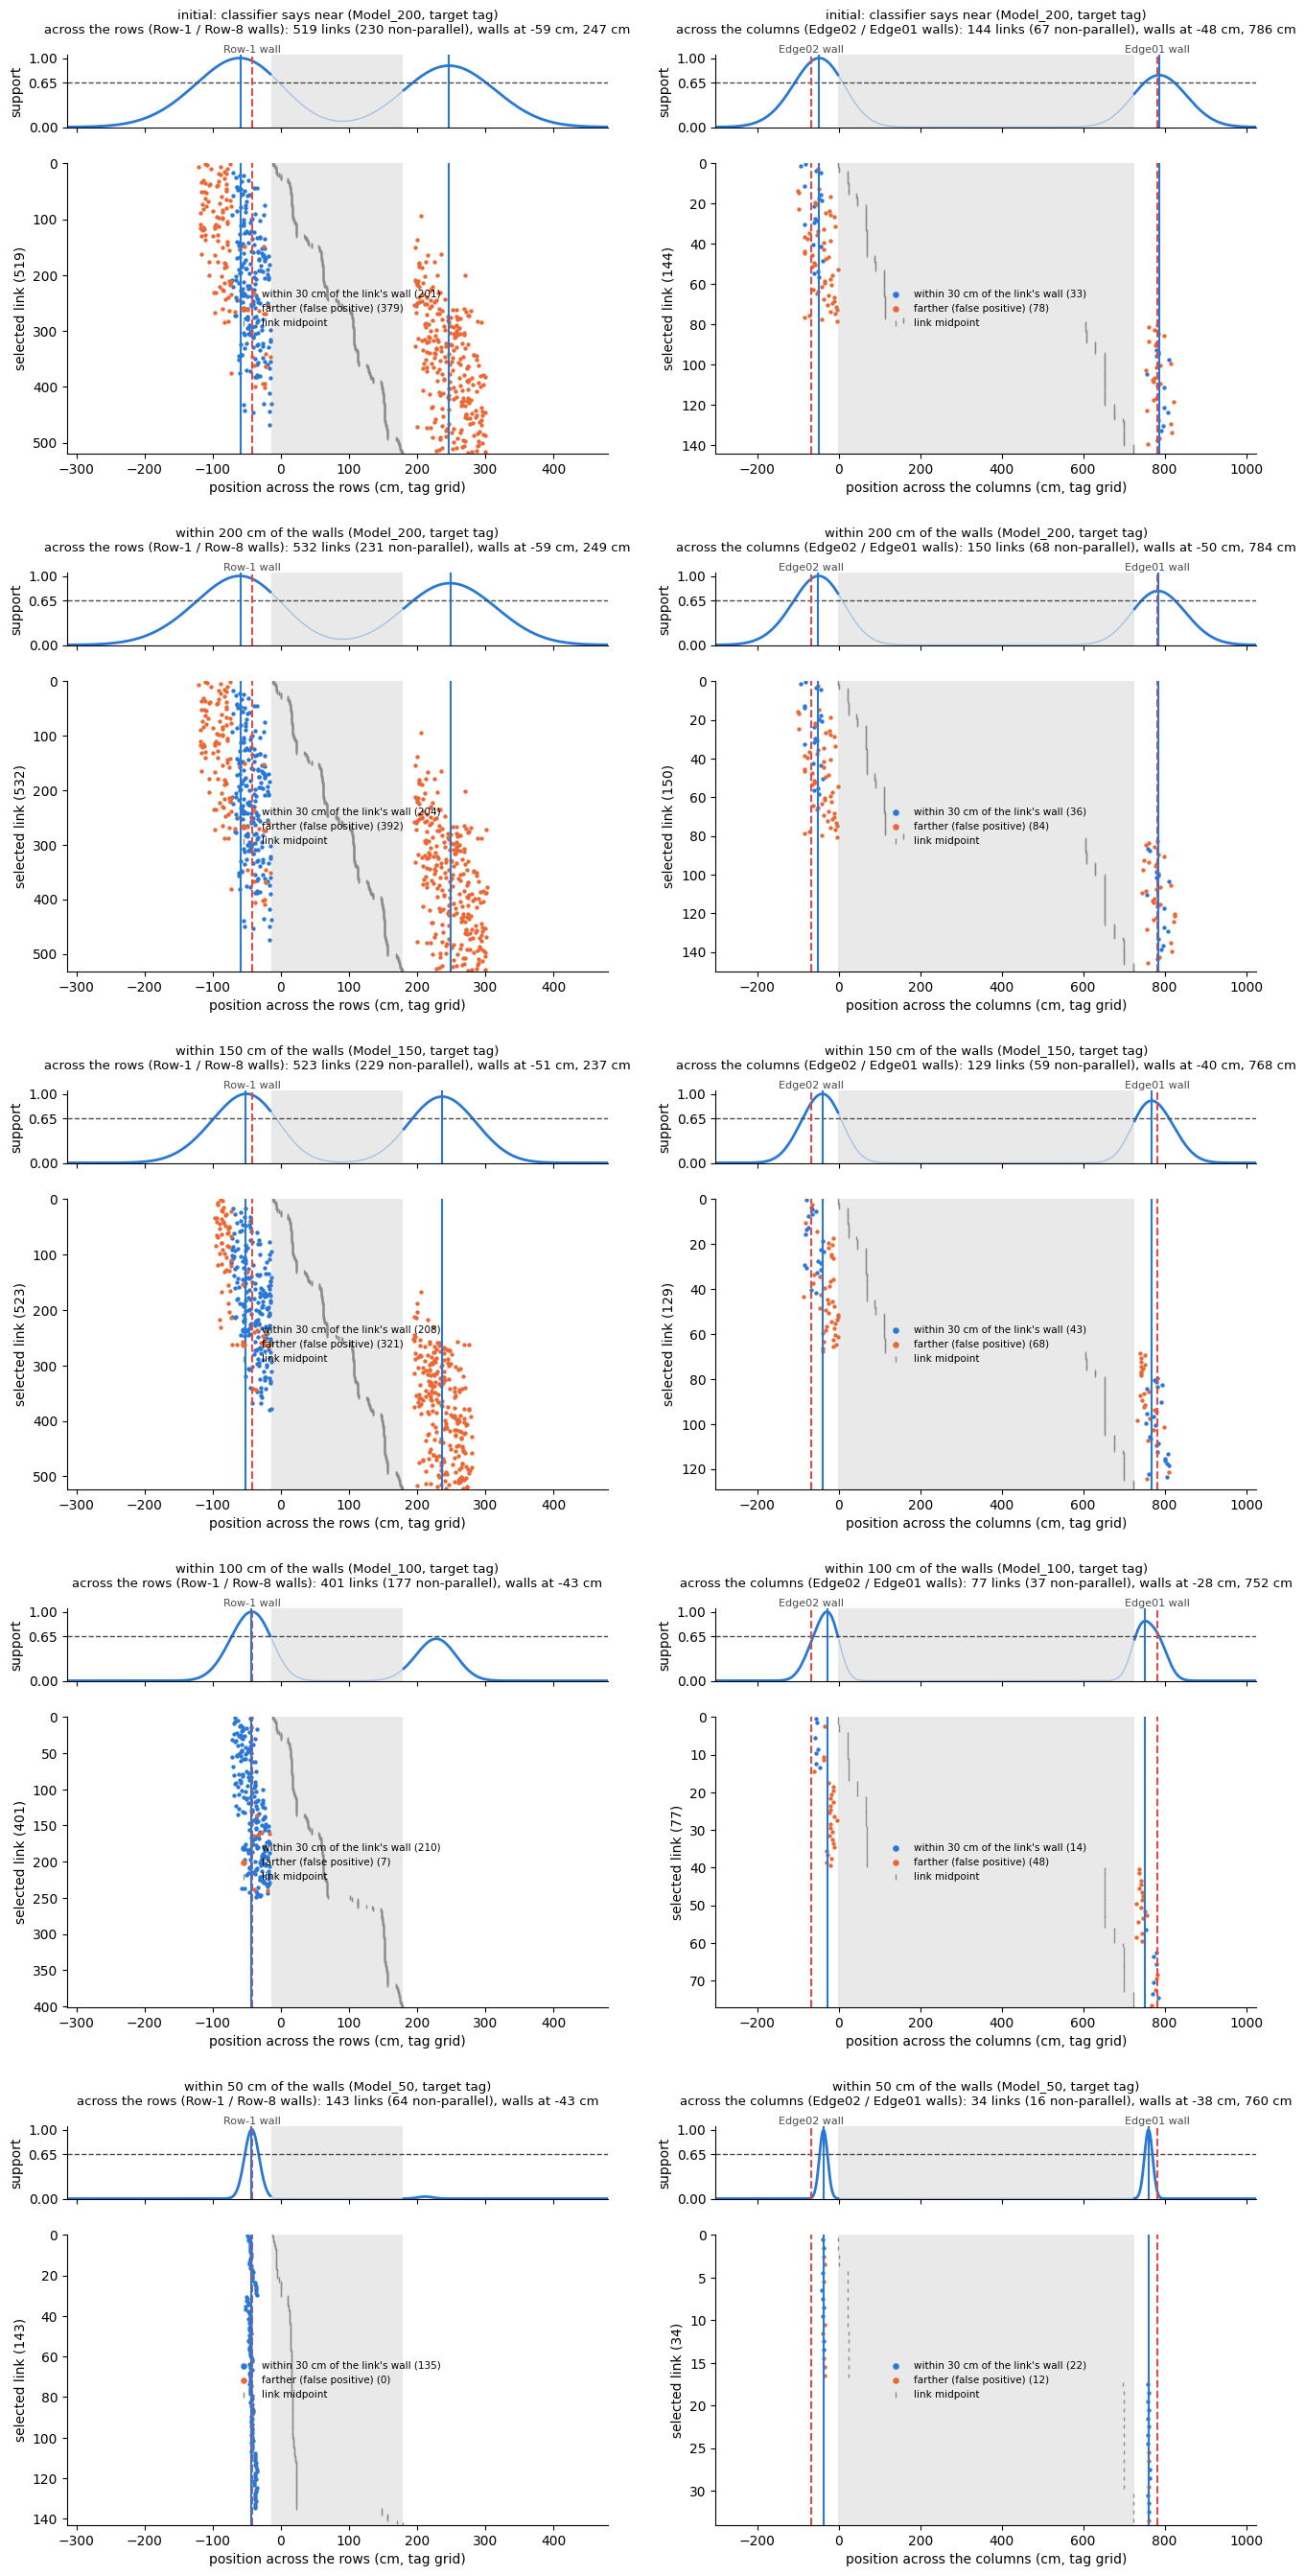

In [8]:
def link_true_pos(target):
    # the true wall of every link under the target: (axis, position on it); scoring only
    names = TRUTH[target][1]
    return np.array([WALL_AXIS[n] for n in names]), np.array([TRUE_GRID[WALL_AXIS[n]][n.split(" (")[0]] for n in names])

def plot_stages(stages, target):
    t_axis, t_pos = link_true_pos(target)
    fig = plt.figure(figsize=(16, 5.4 * len(stages)))
    for sf, st in zip(np.atleast_1d(fig.subfigures(len(stages), 1)), stages):
        axes = sf.subplots(2, 2, height_ratios=[1, 4], sharex="col")
        for k, d in enumerate((0, 1)):
            top, ax = axes[0, k], axes[1, k]
            if d not in st["info"]:
                top.set_visible(False); ax.set_visible(False)
                continue
            e, s, (lo, hi) = st["info"][d], S_IT[d], TAGS[d]
            idx = e["idx"]
            correct = (t_axis[idx] == d)[:, None] & (np.abs(e["pos"] - t_pos[idx][:, None]) <= ITER_TOL_CM)
            top.plot(s, np.where(e["beyond"], e["prof"], np.nan), color="#2a78d6", lw=2)
            top.plot(s, np.where(e["beyond"], np.nan, e["prof"]), color="#2a78d6", lw=1, alpha=0.35)
            top.axhline(ITER_CUTOFF, color="#4a4a4a", ls="--", lw=1)
            rows = np.broadcast_to(np.arange(len(idx))[:, None] + 0.5, e["pos"].shape)
            for ok, color, lab in [(True, "#2a78d6", f"within {ITER_TOL_CM} cm of the link's wall"),
                                   (False, "#eb6834", "farther (false positive)")]:
                mm = e["keep"] & (correct == ok)
                ax.scatter(e["pos"][mm], rows[mm], s=10, color=color, lw=0, label=f"{lab} ({mm.sum()})")
            ax.scatter(C[idx, d], np.arange(len(idx)) + 0.5, marker="|", s=10, color="#8a8a8a", lw=1,
                       label="link midpoint")
            for a in (top, ax):
                a.axvspan(lo, hi, color="#8a8a8a", alpha=0.18, lw=0)
                for tw in TRUE_GRID[d].values():
                    a.axvline(tw, color="#e34948", ls="--", lw=1.5)
                for w in st["walls"][d].values():
                    a.axvline(w, color="#2a78d6", lw=1.5)
                for side in ("top", "right"):
                    a.spines[side].set_visible(False)
            xlim = (lo - 300, hi + 300)
            for n, tw in TRUE_GRID[d].items():
                if xlim[0] < tw < xlim[1]:
                    top.text(tw, 1.0, n, transform=top.get_xaxis_transform(), ha="center", va="bottom", fontsize=8,
                             color="#4a4a4a")
            top.set_ylim(0, 1.05); top.set_ylabel("support"); top.set_yticks([0, ITER_CUTOFF, 1])
            est_txt = ", ".join(f"{w:.0f} cm" for w in st["walls"][d].values()) or "none"
            mname = "Model_∞" if st["cap"] is None else f"Model_{st['cap']}"
            n_np = int((~parallel[idx]).sum())
            top.set_title(f"{st['label']} ({mname}, target {target})\n{AXIS[d]}: {len(idx)} links "
                          f"({n_np} non-parallel), walls at {est_txt}", fontsize=9.5, pad=16)
            ax.set_xlim(*xlim); ax.set_ylim(len(idx), 0)
            ax.set_xlabel(f"position {AXIS[d].split(' (')[0]} (cm, tag grid)")
            ax.set_ylabel(f"selected link ({len(idx)})")
            ax.legend(frameon=False, fontsize=7.5, loc="center",
                      bbox_to_anchor=(((lo + hi) / 2 - xlim[0]) / (xlim[1] - xlim[0]), 0.5), markerscale=1.5)
    plt.show()

plot_stages(stages, TARGET)

### Wall error after each step

The distance between each estimated wall and the scanned one, for the three walls that links are near, with one line
per target. An x on the top edge means no wall passed the cutoff on that side at that step. The green band is the
10–15 cm goal. Saved as `reconstruction_nonparallel_out/iteration_wall_error.png`.

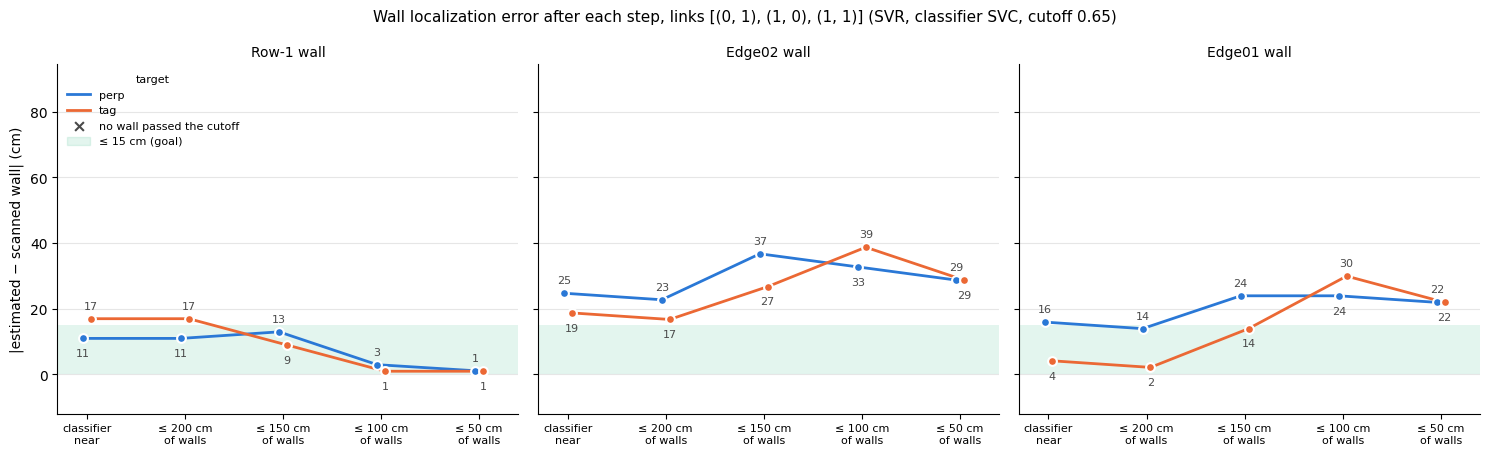

In [9]:
def wall_errors(stages):
    return {name: np.array([abs(st["walls"][d][side] - TRUE_GRID[d][name]) if side in st["walls"][d] else np.nan
                            for st in stages]) for name, d, side in SIDES[:3]}

YCAP = 80
COLORS = {"perp": "#2a78d6", "tag": "#eb6834"}
xlab = ["classifier\nnear"] + ["fallback" if st["cap"] is None else f"≤ {st['cap']} cm\nof walls" for st in stages[1:]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for j, (name, _, _) in enumerate(SIDES[:3]):
    ax = axes[j]
    ax.axhspan(0, 15, color="#1baf7a", alpha=0.12, lw=0)
    for i, t in enumerate(TARGETS):
        e = wall_errors(all_stages[t])[name]
        x = np.arange(len(e)) + (i - 0.5) * 0.08
        col = COLORS[t]
        ok, big, none = np.isfinite(e) & (e <= YCAP), np.isfinite(e) & (e > YCAP), ~np.isfinite(e)
        ax.plot(x, np.where(np.isfinite(e), np.minimum(e, YCAP), np.nan), color=col, lw=2, label=t if j == 0 else None)
        ax.scatter(x[ok], e[ok], s=40, color=col, edgecolor="white", lw=1.5, zorder=3)
        ax.scatter(x[big], np.full(big.sum(), YCAP), s=40, facecolor="white", edgecolor=col, lw=1.5, zorder=3)
        ax.scatter(x[none], np.full(none.sum(), YCAP * 1.1), s=40, marker="x", color=col, lw=1.5, zorder=3)
        other = wall_errors(all_stages[[o for o in TARGETS if o != t][0]])[name]
        for xi, v, w in zip(x, e, other):
            if np.isfinite(v):                                  # the larger of the two above its point, the other below
                below = np.isfinite(w) and (v < w or (v == w and i == 1))
                ax.annotate(f"{v:.0f}", (xi, min(v, YCAP)), xytext=(0, -13 if below else 7), textcoords="offset points",
                            ha="center", fontsize=8, color="#4a4a4a")
    ax.set_xticks(range(len(xlab)), xlab, fontsize=8)
    ax.set_xlim(-0.3, len(xlab) - 0.6); ax.set_ylim(-12, YCAP * 1.18)
    ax.set_title(name, fontsize=10)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("|estimated − scanned wall| (cm)")
axes[0].scatter([], [], s=40, marker="x", color="#4a4a4a", label="no wall passed the cutoff")
axes[0].fill_between([], [], color="#1baf7a", alpha=0.12, label="≤ 15 cm (goal)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left", title="target", title_fontsize=8)
fig.suptitle(f"Wall localization error after each step, links {sorted(LINK_OFFSETS)} ({MODEL}, classifier "
             f"{CLASSIFIER}, cutoff {ITER_CUTOFF:g})", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "iteration_wall_error.png", dpi=150)
plt.show()

### Final estimated walls on the room (`TARGET`)

The scanned room (grey, points at 1–2 m height) with each side's final wall (blue). A side keeps its last estimate
through later steps that have no candidates on that side. A step that has candidates there, none reaching the
cutoff, rejects it. No ground truth is used for this. Each is labelled with its distance to the nearest scanned wall (red dashed), or "false wall" when none is
within 100 cm, and the step it comes from. Saved as `reconstruction_nonparallel_out/iteration_room_map.png`.

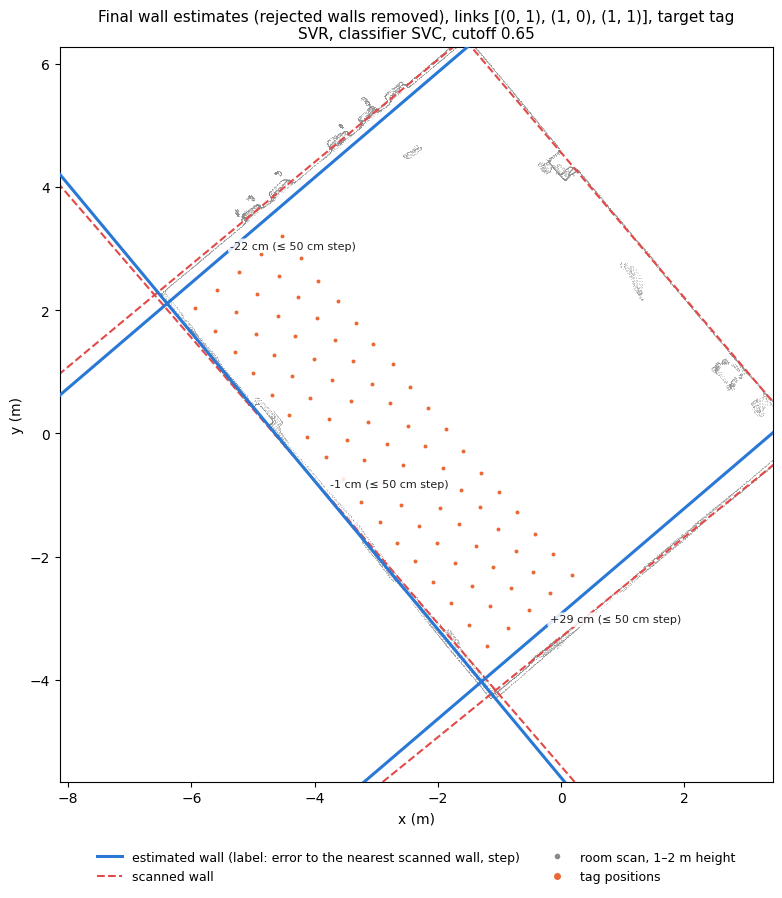

In [10]:
verts = np.asarray(o3d.io.read_triangle_mesh(str(MESH_PATH)).vertices)
room = verts[(verts[:, 2] > WALL_Z[0]) & (verts[:, 2] < WALL_Z[1])][:, :2]
corners = np.array([grid_xy(c, r) for c in (0, N_COLS - 1) for r in (0, N_ROWS - 1)])
lo_xy, hi_xy = corners.min(0) - 2.2, corners.max(0) + 2.2
room = room[((room > lo_xy) & (room < hi_xy)).all(1)]
room = room[np.random.default_rng(0).choice(len(room), min(len(room), 40000), replace=False)]

def wall_line(d, s, half=12):
    v = np.array([-U[d][1], U[d][0]])
    Pt = O + s / 100 * U[d]
    return Pt + np.outer([-half, half], v), Pt + ((M_ALL - Pt) @ v) * v

def nearest_true(d, s):
    name = min(TRUE_GRID[d], key=lambda n: abs(TRUE_GRID[d][n] - s))
    return name, s - TRUE_GRID[d][name]

def final_walls(stages):
    # a side keeps its last estimate while later steps have no candidates there; a step whose candidates on that
    # side do not reach the cutoff rejects it
    final = {0: {}, 1: {}}
    for k, st in enumerate(stages):
        step = "fallback" if st["cap"] is None else "classifier" if k == 0 else f"≤ {st['cap']} cm"
        for d in (0, 1):
            for side in ("low", "high"):
                if side in st["walls"][d]:
                    final[d][side] = (st["walls"][d][side], step)
                elif d in st["info"] and st["info"][d]["voted"][side]:
                    final[d].pop(side, None)
    return final

fig, ax = plt.subplots(figsize=(10, 9))
ax.scatter(*room.T, s=0.3, color="#8a8a8a", alpha=0.4, lw=0, rasterized=True)
for wname, (p, n, d) in walls.items():
    ax.plot(*wall_segment(p, n, 12).T, color="#e34948", lw=1.5, ls="--")
ax.scatter(*tag_xy.T, s=8, color="#eb6834", lw=0, zorder=3)
for d, sides in final_walls(stages).items():
    for side, (s, step) in sides.items():
        seg, at = wall_line(d, s)
        ax.plot(*seg.T, color="#2a78d6", lw=2.2, zorder=4)
        name, err = nearest_true(d, s)
        txt = (f"{err:+.0f} cm" if abs(err) <= 100 else "false wall") + f" ({step} step)"
        ax.annotate(txt, at, xytext=(4, 4), textcoords="offset points", fontsize=8, color="#1f1f1f", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_xlim(lo_xy[0], hi_xy[0]); ax.set_ylim(lo_xy[1], hi_xy[1]); ax.set_aspect("equal")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
handles = [plt.Line2D([], [], color="#2a78d6", lw=2.2, label="estimated wall (label: error to the nearest scanned wall, step)"),
           plt.Line2D([], [], color="#e34948", lw=1.5, ls="--", label="scanned wall"),
           plt.Line2D([], [], color="#8a8a8a", marker="o", ls="none", ms=3, label="room scan, 1–2 m height"),
           plt.Line2D([], [], color="#eb6834", marker="o", ls="none", ms=4, label="tag positions")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0))
ax.set_title(f"Final wall estimates (rejected walls removed), links {sorted(LINK_OFFSETS)}, target {TARGET}\n"
             f"{MODEL}, classifier {CLASSIFIER}, cutoff {ITER_CUTOFF:g}", fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(OUT / "iteration_room_map.png", dpi=130)
plt.show()

### Reading the results (run saved here: 46 cm parallel + 65 cm diagonal links, SVR, SVC, cutoff 0.65)

Estimated minus scanned wall, per step:

| step | perp: Row-1 | Edge02 | Edge01 | tag: Row-1 | Edge02 | Edge01 |
|---|---|---|---|---|---|---|
| 0. classifier near | −11 | +25 | −16 | −17 | +19 | +4 |
| 1. ≤ 200 cm | −11 | +23 | −14 | −17 | +17 | +2 |
| 2. ≤ 150 cm | −13 | +37 | −24 | −9 | +27 | −14 |
| 3. ≤ 100 cm | −3 | +33 | −24 | −1 | +39 | −30 |
| 4. ≤ 50 cm | +1 | +29 | −22 | −1 | +29 | −22 |

- **Edge02 is never lost.** With parallel links only, it dropped out at ≤ 100 cm. The diagonals give it enough
  support at every step.
- **The false wall (Row-8 side) is rejected at ≤ 100 cm under both targets,** while links still vote there. The
  three real walls are never rejected. So the room map can drop rejected walls, with no ground truth involved.
- **`tag` is the default (`TARGET`).** Its walls are closer at the first three steps: the mean of the three walls
  is 12 cm at ≤ 200 cm, against 16 cm for `perp`. The final step is the same for both.
- **`tag` makes the classifier step trivial.** 97% of the links have a tag within 200 cm of some wall, so
  "classifier says near" is nearly all links.
- **`perp`'s Model_100 is the only model clearly better than the mean of train:** 11.5 against 17.4 cm. Every
  other Model_X is within a few cm of the mean, for both targets.
- **The ≤ 50 cm step is snapping, not RF.** Model_50 predicts a near-constant distance (MAE about 1 cm, the same as
  the mean). Every link set and both targets end at Row-1 ±1, Edge02 +29 and Edge01 −22 cm. Under `perp`, no
  diagonal is within 50 cm: a 45° ray from the row next to a wall is about 82 cm long.

**Other link sets** (prototype runs with the same code, changing `LINK_OFFSETS`). Each cell is the error after the
≤ 200 cm step, Row-1 / Edge02 / Edge01, in cm:

| links | perp | tag |
|---|---|---|
| 46 cm parallel only | −19 / +7 / +2 | −13 / +17 / +10 |
| 46 + 65 cm (saved here) | −11 / +23 / −14 | −17 / +17 / +2 |
| 65 cm diagonals only | −5 / +39 / −24 | −17 / +25 / +2 |
| 65 + 103 cm (non-parallel only) | +3 / +41 / −30 | −17 / +17 / −8 |
| all up to 103 cm | +1 / +25 / −16 | −17 / +15 / −6 |